# 04 - Porosity

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/04_porosity.ipynb)

**Part A - Petrophys Curriculum - Foundations**

Porosity is the fraction of rock volume that is pore space, and it carries the
storage term of every volumetric estimate: hydrocarbon volume scales with
$\phi\,(1-S_w)$, and both saturation and permeability estimates are built on it.
This lesson builds porosity three
independent ways (density, neutron, sonic), reconciles them into a **total** porosity,
strips out clay-bound water to get **effective** porosity, and shows the
**hydrocarbon correction** that applies where light HC distorts the raw logs.

We use `petrophys.interpretation.porosity` and `petrophys.interpretation.porosity.hydrocarbon_correction`,
and we reuse the clay volume (Vcl) built in **lesson 03**.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Read the porosity curves of `pp.interpret` - density `PHID`, neutron `PHIN`, sonic
  `PHIS`, total `PHIT` and effective `PHIE` - and the equations its trace records.
- See how the **matrix density** moves density porosity (`rho_ma`) and how the neutron
  matrix point standardizes neutron porosity (`nphi_ma`).
- Understand **sonic porosity** from DTC with the Wyllie time-average equation.
- Understand how neutron and density combine into **total porosity**, and how the gas
  setting `hc_type` changes it in neutron-density crossover.
- Strip clay-bound water from total porosity with Vcl to get **effective porosity**, and
  see what the clay porosity `phi_cl` does.
- Know what the **hydrocarbon correction** of the raw logs (`apply_hc_correction`) needs.
- **Compare** the three porosity logs on one plot, read where they diverge (gas
  crossover, shale), and **classify** the result (`classify_porosity`).

## Why this matters (the physics)

No single tool measures porosity directly; each infers it from a bulk property:

| Log | Equation | Reads porosity **high** when... | Reads **low** when... |
|-----|----------|-------------------------------|------------------------|
| **Density** (RHOB) | $\phi_D=\dfrac{\rho_{ma}-\rho_b}{\rho_{ma}-\rho_{fl}}$ | light HC (low $\rho$) is present | matrix denser than assumed |
| **Neutron** (NPHI) | $\phi_N = \mathrm{NPHI} - \phi_{N,ma}$ | clay-bound / bound water present | gas (low hydrogen index) |
| **Sonic** (DTC) | $\phi_S=\dfrac{\Delta t-\Delta t_{ma}}{\Delta t_{fl}-\Delta t_{ma}}$ | uncompacted sediments (compaction correction needed) | vugs / fractures: the first arrival bypasses them, so the porosity deficit ($\phi_{total}-\phi_S$, Exercise 3) estimates the secondary porosity |

Because their errors point in *different directions*, the way the three curves
separate is itself diagnostic:

- **Gas effect:** density reads high, neutron reads low -> the classic
  neutron-density **crossover**.
- **Shale:** neutron reads high (clay-bound water), density reads slightly high ->
  they **converge or cross the other way**.

That is why we always look at them together.

### Prerequisites

This lesson assumes **lesson 01** (data access), **lesson 02** (QC), and
especially **lesson 03** (clay volume): the same interpretation computes the Vcl that
turns total into effective porosity, with the Larionov-older GR transform chosen there.
Teaching well: the clastic **30/6-5** (GeoLink, depths in metres); statistics are
reported over its Brent Group, 2841-2958 m. The setup cell hides only the SWC/SOC
core-saturation unit note explained in lessons 00 and 02.

In [2]:
import warnings
import pandas as pd
import petrophys as pp

warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")
well = pp.read(pp.sample("30_6-5"))

One interpretation computes every porosity curve. The trace of its `porosity` step lists
the equations and choices it made:

In [3]:
result = pp.interpret(well, gr_method="larionov_older")
result.step("porosity").decisions

['Initial porosity pass used an available lithology log for matrix endpoints',
 'PHIN = clip(NPHI - nphi_ma(depth), 0, 0.6) using lithology-specific matrix neutron endpoints',
 'PHID = (rho_ma(depth) - RHOB) / (rho_ma(depth) - rho_fl)',
 'PHIS from Wyllie time-average equation using dt_ma(depth)',
 'PHIT = adaptive(PHIN, PHID) with per-sample fallback: density_from_missing_phin=4755, density_from_gas_crossover=14, weighted_nd=17402, neutron_from_missing_phid=5, nan=0',
 'PHIE = PHIT - VCL * phi_cl (0.231)',
 'phi_cl averaged over the shale samples recomputed on the sandstone matrix endpoints of the PHIT it corrects',
 'PHI_SEC = PHIT - PHIS']

## Step 1 - Density porosity

Density porosity inverts the bulk-density mixing law:

$$ \phi_D = \frac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_{fl}} $$

The two parameters that matter are the **matrix density** $\rho_{ma}$ (2.65 quartz,
2.71 calcite, 2.87 dolomite) and the **fluid density** $\rho_{fl}$ (1.0 fresh water,
~1.1 brine, ~0.8 oil, ~0.2 gas). 30/6-5 is a clastic well, and because it carries a
lithology log the trace above reads `rho_ma(depth)`: each sample takes the matrix of its
lithology group (2.65 for sandstone and shale, 2.71 for limestone beds). The fluid
density is `rho_fl` (default 1.0). Setting `rho_ma` holds one matrix density at every
depth, which shows how much the assumption matters.

In [4]:
by_matrix = {rho_ma: pp.interpret(well, rho_ma=rho_ma) for rho_ma in [2.65, 2.71, 2.87]}
pd.concat({rho_ma: run.statistics("PHID", top=2841, bottom=2958) for rho_ma, run in by_matrix.items()})

,,unit,samples,mean,p10,median,p90
2.65,PHID,v/v,768,0.159020,0.037008,0.181536,0.246468
2.71,PHID,v/v,768,0.188222,0.070797,0.210254,0.272908
2.87,PHID,v/v,768,0.257676,0.150301,0.277826,0.335119


Notice how much the matrix assumption moves porosity: over the Brent Group the mean
density porosity rises from 0.159 with quartz (2.65) to 0.188 with calcite (2.71) and
0.258 with dolomite (2.87). Choosing limestone instead of sandstone adds about 3 porosity
units. Choosing the matrix correctly (from lithology, PEF, or crossplots) is essential.

## Step 2 - Neutron porosity and standardization

The neutron tool responds to hydrogen index and is recorded against an assumed matrix
calibration - very often **limestone units**, even in a sandstone well. On a limestone
scale, quartz reads about -0.02, and a water-filled sandstone reads roughly **4 porosity
units too low** at reservoir porosities, so the neutron must be **standardized** to the
true matrix before comparison with density.

`pp.interpret` computes $\phi_N = \mathrm{NPHI} - \phi_{N,ma}$, clipped to [0, 0.6].
The matrix point $\phi_{N,ma}$ (`nphi_ma`) follows the lithology: -0.02 for sandstone and
shale, 0 for limestone. That removes the quartz offset, not the full sandstone shift;
`nphi_ma=-0.04` applies the 4-unit standardization at every depth.

In [5]:
standardized = pp.interpret(well, nphi_ma=-0.04)
pd.concat({"nphi_ma by lithology": result.statistics(["NPHI", "PHIN"], top=2841, bottom=2958),
           "nphi_ma -0.04": standardized.statistics(["NPHI", "PHIN"], top=2841, bottom=2958)})

unit  samples      mean       p10    median  \
nphi_ma by lithology NPHI  v/v      768  0.242378  0.189847  0.222915   
                     PHIN  v/v      768  0.262196  0.209430  0.242915   
nphi_ma -0.04        NPHI  v/v      768  0.242378  0.189847  0.222915   
                     PHIN  v/v      768  0.282378  0.229847  0.262915   

                                p90  
nphi_ma by lithology NPHI  0.313313  
                     PHIN  0.333313  
nphi_ma -0.04        NPHI  0.313313  
                     PHIN  0.353313

> **Which neutron do I feed downstream?** The 30/6-5 header does not state the neutron's
> calibration matrix. The library treats NPHI as limestone-referenced, so the default
> PHIN adds 0.02 to the Brent mean (0.242 to 0.262). Know what that costs: in clean
> sandstone a limestone-scale neutron still reads about 0.02 low against the sandstone
> density porosity, so the neutron-density blend slightly understates porosity and the
> pair looks closer to crossover than it is. `nphi_ma=-0.04` removes that offset (mean
> 0.282) when you want a fully sandstone-referenced neutron.

## Step 3 - Sonic porosity (Wyllie time-average)

Sonic porosity uses transit time (slowness) via the Wyllie time-average equation:

$$ \phi_S = \frac{\Delta t - \Delta t_{ma}}{\Delta t_{fl} - \Delta t_{ma}} $$

with matrix slowness $\Delta t_{ma}$ (55.5 sandstone, 47.6 limestone, 43.5 dolomite
us/ft; `dt_ma`, by lithology unless set) and fluid slowness $\Delta t_{fl}$ (`dt_fl`,
189 us/ft). `pp.interpret` writes it as `PHIS`. Sonic porosity responds mainly to
**primary** (intergranular) porosity and tends to miss isolated vugs and fractures; in
uncompacted rock it reads high and needs a compaction factor. The difference
`PHI_SEC = PHIT - PHIS` estimates the secondary porosity.

## Step 4 - Comparing the three porosity logs

The key diagnostic plot: density, neutron and sonic porosity in one track, next to
the gamma ray, over 2800-3000 m around the Brent Group. Porosity increases to the left.
Watch for:

- **Neutron-density crossover** (PHID left of PHIN): light hydrocarbon / gas.
- **Neutron far left of density:** shale (clay-bound water inflates neutron), as in the
  high-GR beds above 2841 m and below 2958 m.
- **Sonic diverging high:** uncompacted intervals (compaction correction needed).
- **Sonic diverging low:** secondary porosity (vugs/fractures) that the first
  arrival bypasses.

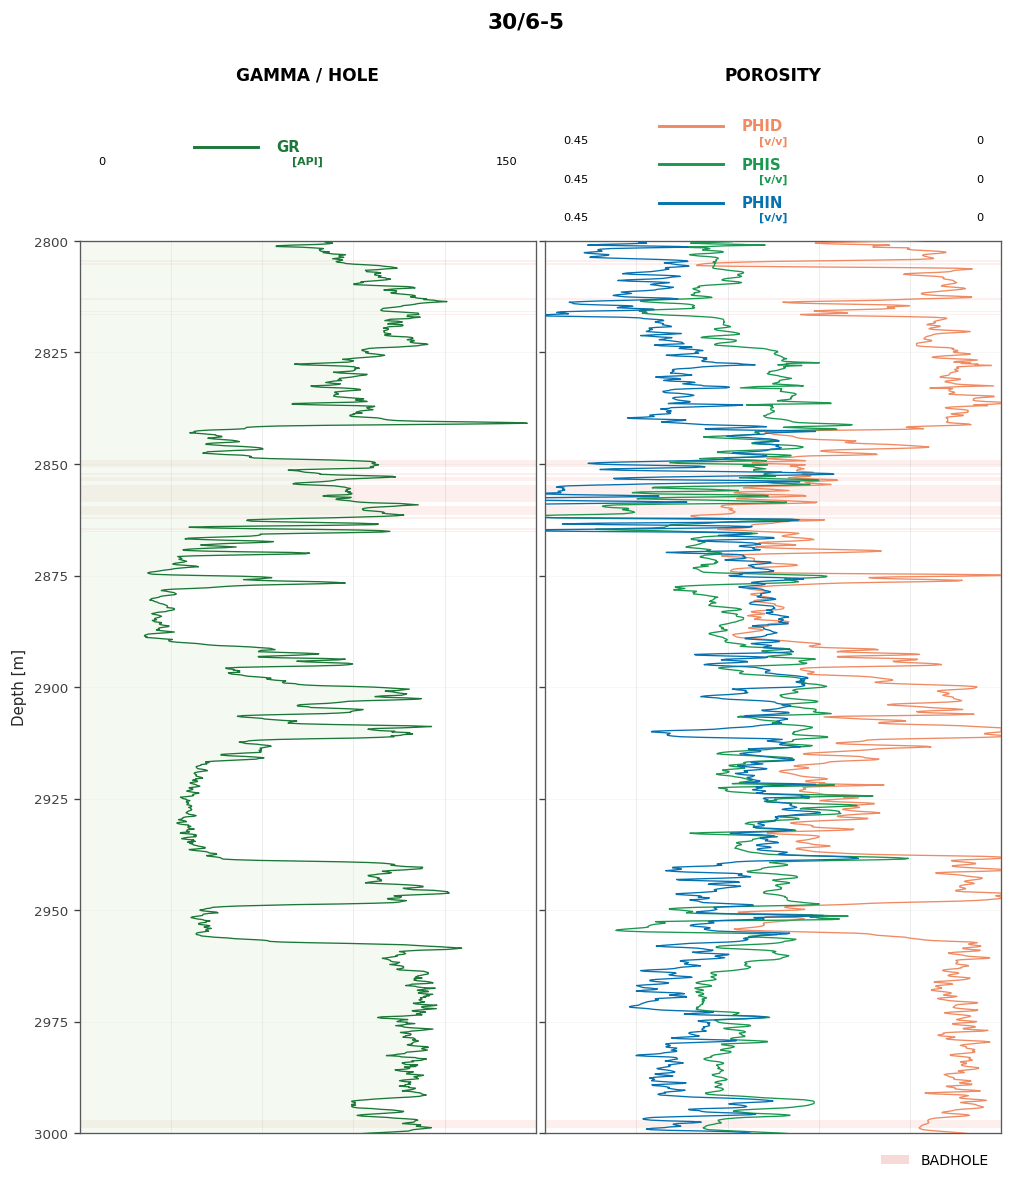

In [6]:
pp.plot(result, curves=["GR", "PHID", "PHIN", "PHIS"], top=2800, bottom=3000, figsize=(8, 10))

In [7]:
result.statistics(["PHID", "PHIN", "PHIS", "PHIT", "PHIE"], top=2841, bottom=2958)

,unit,samples,mean,p10,median,p90
PHID,v/v,768,0.159289,0.037008,0.181742,0.246468
PHIN,v/v,768,0.262196,0.209430,0.242915,0.333313
PHIS,v/v,768,0.247456,0.189157,0.244112,0.310581
PHIT,v/v,768,0.200452,0.129854,0.203638,0.263334
PHIE,v/v,768,0.141074,0.000000,0.164457,0.234603


### Where do they diverge? (gas vs shale)

In the shales the neutron reads 0.30-0.45 while the density porosity falls below 0.1:
the shale signature. In the clean sands the three logs converge, and over the Brent Group
the mean PHID (0.159) stays below the mean PHIN (0.262): no gas.

The run flags the gas signature itself in `CROSSOVER_FLAG`: PHID - PHIN > 0.05 in
clean (VCL < 0.35), porous (PHIE > 0.05), good-hole rock. Its mean is the flagged share
of the samples with a value; in 30/6-5 almost none qualify.

In [8]:
result.statistics("CROSSOVER_FLAG")

,unit,samples,mean,p10,median,p90
CROSSOVER_FLAG,,17416,0.000402,0.0,0.0,0.0


#### Interpreting neutron-density separation

Positive density-neutron separation identifies candidate gas-affected samples,
but it is not proof of hydrocarbons without supporting resistivity and hole-
quality evidence. Strong negative separation is more consistent with clay-rich,
low-quality rock. The bundled well 25_5-1 carries a real crossover cluster
(about 3018-3045 m), used in the next step.

## Step 5 - Total porosity

`pp.interpret` combines neutron and density into one total porosity `PHIT` with an
adaptive rule:

- where the logs cross over (PHID > PHIN + 0.05, the **gas** signature), it takes
  density porosity with the default `hc_type="oil"`, and with `hc_type="gas"` the
  root-mean-square $\sqrt{(\phi_D^2 + \phi_N^2)/2}$ (Gaymard and Poupon, 1968), which
  balances the density reading too high against the neutron reading too low;
- otherwise it uses the shale-tolerant weighted average $0.6\,\phi_D + 0.4\,\phi_N$;
- where one log is missing, the other alone.

The trace above counts the samples each branch took: 17402 weighted, 4755 density only
(no neutron), 14 in crossover.

Well 25_5-1 shows the gas setting at work. The first plot shows its crossover (shaded)
between about 3018 and 3045 m, in a clean (low GR), resistive sand; the second compares PHIT of two
runs, `hc_type="oil"` and `hc_type="gas"`. Interpreting 25_5-1 also reports a real data
finding: 58 `RMED` samples pegged at the 2000 ohm.m tool ceiling are removed.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1173: DataQualityWarning: RMED: 58 of 18648 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)


[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1173: DataQualityWarning: RMED: 58 of 18648 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)


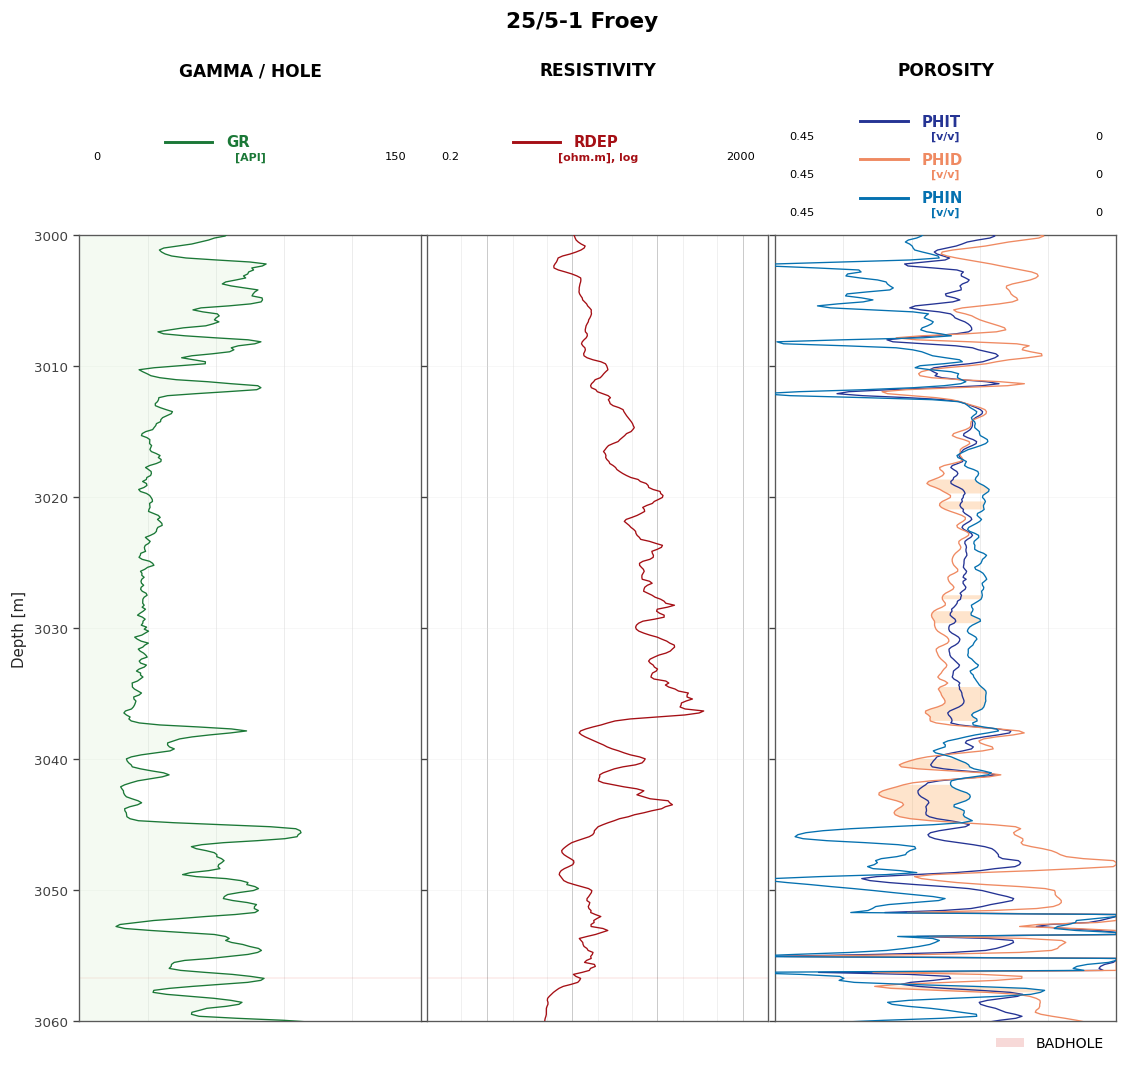

In [9]:
gas_well = pp.read(pp.sample("25_5-1"))
by_fluid = {hc_type: pp.interpret(gas_well, hc_type=hc_type) for hc_type in ["oil", "gas"]}
pp.plot(by_fluid["gas"], curves=["GR", "RDEP", "PHID", "PHIN", "PHIT"], top=3000, bottom=3060, figsize=(9, 9))

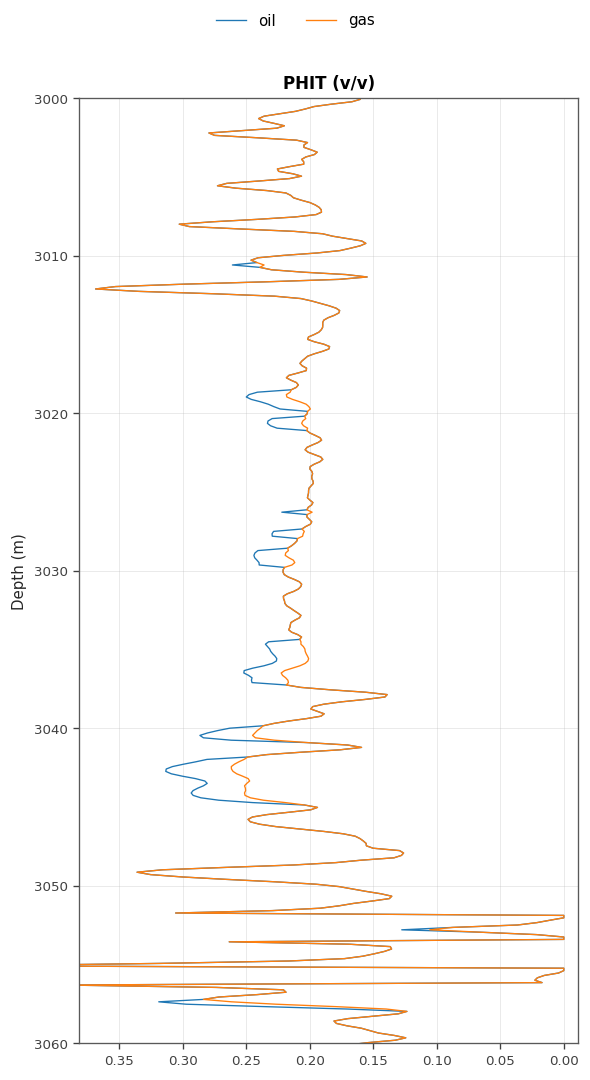

In [10]:
pp.plot(by_fluid, curves=["PHIT"], top=3000, bottom=3060, figsize=(5, 9))

The two runs differ only in the crossover samples. There density porosity alone reads up
to about 0.31, while the root-mean-square stays near 0.25, between the too-high density
and the too-low neutron. Over 3018-3045 m the mean PHIT falls from 0.223 to 0.211:
choosing the fluid is choosing the porosity of the gas zone.

In [11]:
pd.concat({hc_type: run.statistics("PHIT", top=3018, bottom=3045) for hc_type, run in by_fluid.items()})

,,unit,samples,mean,p10,median,p90
oil,PHIT,v/v,177,0.222601,0.193638,0.214977,0.280668
gas,PHIT,v/v,177,0.210736,0.193638,0.206880,0.245590


## Step 6 - Effective porosity

**Total** porosity includes clay-bound water, which is immovable and does not
contribute to flow. **Effective** porosity removes it:

$$ \phi_e = \phi_t - V_{cl}\cdot\phi_{clay} $$

where $\phi_{clay}$ (`phi_cl`) is the porosity of pure clay. Unset, the workflow derives
it from the well's shale samples - 0.231 in 30/6-5, as the trace above records - and
0.15 is the last resort. The result is clipped to $[0,\ \phi_t]$, so high-Vcl rock
cannot go negative. This is the number that goes into net-pay and hydrocarbon volume
calculations. The plot shows VCL beside PHIT and PHIE; the gap between the two porosity
curves is the clay-bound water.

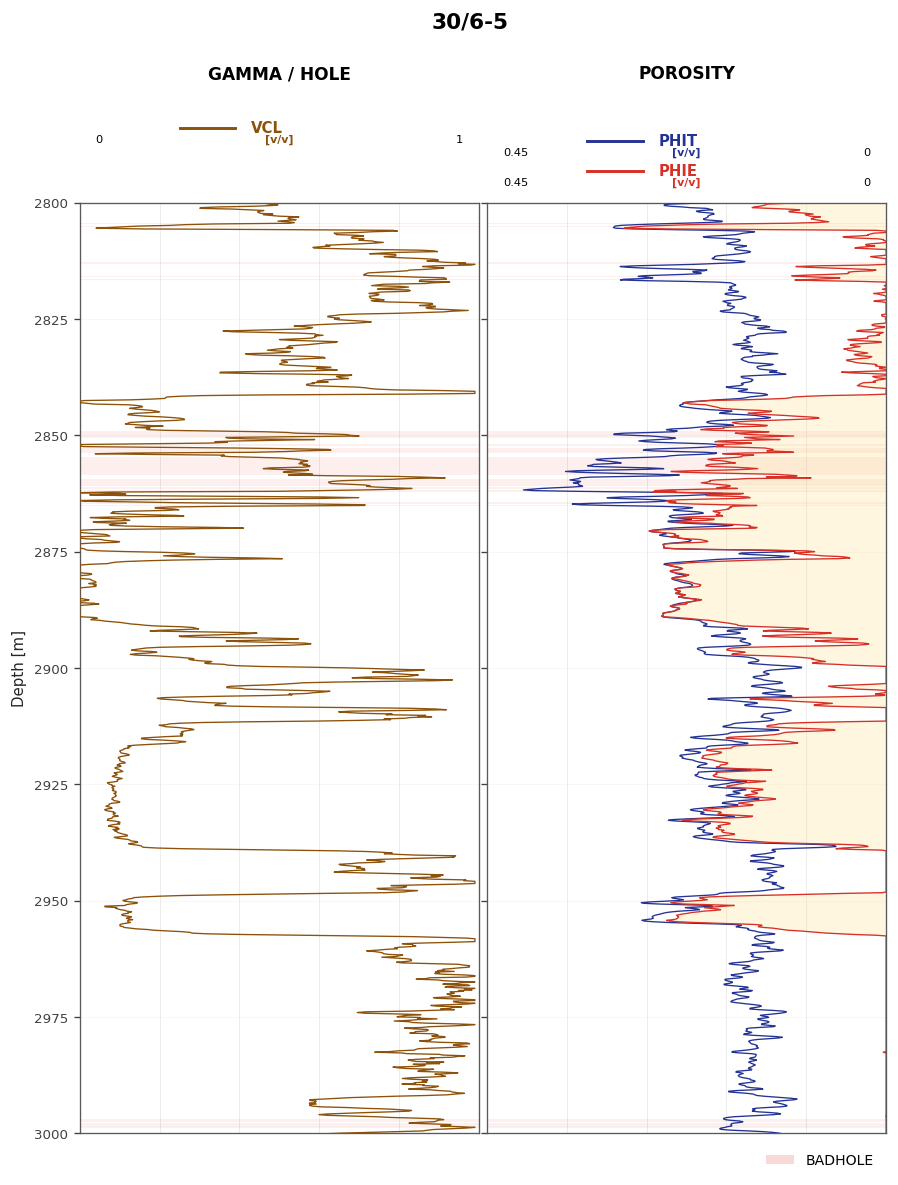

In [12]:
pp.plot(result, curves=["VCL", "PHIT", "PHIE"], top=2800, bottom=3000, figsize=(7, 10))

A smaller clay porosity removes less water. With `phi_cl=0.15` the Brent mean PHIE
rises from 0.141 to 0.157:

In [13]:
fixed_phi_cl = pp.interpret(well, gr_method="larionov_older", phi_cl=0.15)
pd.concat({"phi_cl from the shales": result.statistics("PHIE", top=2841, bottom=2958),
           "phi_cl 0.15": fixed_phi_cl.statistics("PHIE", top=2841, bottom=2958)})

,,unit,samples,mean,p10,median,p90
phi_cl from the shales,PHIE,v/v,768,0.141074,0.00000,0.164457,0.234603
phi_cl 0.15,PHIE,v/v,768,0.156914,0.02306,0.180181,0.240651


## Step 7 - Hydrocarbon correction

Light hydrocarbon (especially **gas**) has a low density and a low hydrogen index, so
it makes the density log read **too porous** and the neutron log read **too tight**.
Where gas is present the raw logs are corrected before porosity is recomputed.

The correction scales with the hydrocarbon left in the flushed zone, `1 - Sxo`, so it
needs a **flushed-zone water saturation** curve (`SXO`, from a micro-resistivity log).
`apply_hc_correction=True` runs it before saturation and the porosity step then reads the
corrected `NPHI_HC` and `RHOB_HC`; `hc_type`, `rho_hc` and `hc_hydrogen_index` set the
fluid. 30/6-5 carries no `SXO` curve, so the step is skipped and the run says why:

In [14]:
pp.interpret(well, apply_hc_correction=True).warnings[0]

'hc_correction not applied: Missing a flushed-zone water saturation curve (SXO), as the step runs before saturation'

Apply it only where the logs show gas (neutron-density crossover): a flat Sxo applied
to the whole well moves NPHI everywhere, not just in the gas zones.

## Step 8 - Classifying porosity

`classify_porosity` bins porosity into reservoir-quality categories:

- `EXCELLENT` : > 20%
- `GOOD`      : 12-20%
- `FAIR`      : 6-12%
- `POOR`      : <= 6%

We classify the **effective** porosity, since that is the flow-relevant number, over the
Brent Group, 2841-2958 m (Ness and Etive formations), which is the interval an
interpreter would actually report. Above the reservoir, the shallow, poorly consolidated
section reads very high apparent porosity that says nothing about reservoir quality.

In [15]:
from petrophys.interpretation.porosity import classify_porosity

pd.Series(classify_porosity(result.well["PHIE"].depth_slice(2841, 2958).data)).value_counts()

PorosityClassification.GOOD         324
PorosityClassification.EXCELLENT    194
PorosityClassification.POOR         159
PorosityClassification.FAIR          91
Name: count, dtype: int64

Of the 768 Brent samples, 194 (25%) are excellent and 324 (42%) good: the clean Ness and
Etive sands. The 159 poor samples (21%) are the shale, silt and coal beds between them.

## Pitfalls and parameter choices

- **Matrix density / slowness is the biggest lever.** Sandstone vs dolomite shifts
  porosity by several units. Set it from lithology, PEF, or crossplots - never assume.
- **Standardize the neutron log** to the true matrix before comparing with density,
  or the pair will look artificially crossed-over or converged.
- **Gas crossover is signal, not noise.** The adaptive total-porosity rule and the
  HC correction both exploit it; do not "average it away", and set `hc_type` for the
  fluid you have.
- **Total vs effective.** Report effective porosity for pay and volumetrics; total
  porosity for saturation modelling (which needs the clay-bound water).
- **Sonic misses secondary porosity.** In vuggy / fractured rock, PHIS < PHIT; the
  difference (`PHI_SEC`) estimates secondary porosity.
- **HC correction needs Sxo.** 30/6-5 has no `SXO` curve, so the step is skipped; in
  practice Sxo comes from a micro-resistivity log through a flushed-zone saturation model.

## Recap

- One `pp.interpret` run builds porosity three independent ways: **density** (`PHID`,
  `rho_ma`, `rho_fl`), **neutron** (`PHIN`, `nphi_ma`) and **sonic** (`PHIS`, Wyllie,
  `dt_ma`, `dt_fl`), and its trace records each equation.
- Plotted them together and read the divergences: neutron-density **crossover = gas**,
  neutron-over-density **= shale**.
- Combined neutron + density into **total porosity** (`PHIT`, adaptive; `hc_type` in
  crossover) and stripped clay-bound water into **effective porosity** (`PHIE`, `phi_cl`)
  using the Vcl of lesson 03.
- The **gas HC correction** (`apply_hc_correction`) needs a flushed-zone Sxo curve and
  belongs only in flagged gas zones.
- Classified effective porosity into reservoir-quality bins (`classify_porosity`).

## Try it yourself

> **Exercise 1.** Interpret 30/6-5 with `rho_fl=1.1` (brine) instead of the default 1.0.
> How many porosity units does the Brent mean PHID change, and why?
>
> **Exercise 2.** Interpret 25_5-1 with `rho_ma=2.65` and compare its crossover
> (`CROSSOVER_FLAG`) over 3018-3045 m with the lithology-dependent run. Does the gas
> signature depend on the matrix assumption?
>
> **Exercise 3.** Plot `PHI_SEC` (PHIT - PHIS) of 30/6-5 with
> `pp.plot(result, curves=["PHIT", "PHIS", "PHI_SEC"], ...)`. Where in the well does sonic
> under-read total porosity?

## What's next

With clay volume and porosity in hand, the next foundation is **lithology**: which
minerals make up the rock matrix. Continue with **lesson 05 - Lithology and the
multi-mineral solver** (`05_lithology_and_mineral_solver.ipynb`), which uses
neutron-density and PEF crossplots to solve for mineral volumes instead of assuming a
single matrix density. Lesson 06 then covers formation water and temperature, and
lesson 07 turns resistivity into water saturation using the effective porosity and
Vcl produced here.